## Gradient Descent
- Thuật toán hạ gradient là một trong những thuật toán quan trọng nhất trong machine learning và deep learning. Nó giúp mô hình tìm ra bộ tham số tốt nhất bằng cách liên tục điều chỉnh tham số để giảm sai số dự đoán
- Loss function - hàm mất mát: là hàm đo mức độ sai lệch giữa dự đoán và mô hình và giá trị thực tế
- gradient - độ dốc có hướng: cho biết hàm mất mát thay đổi theo hướng nào khi các tham số thay đổi. Nó cung cấp thông tin để thuật toán quyết định hướng điều chỉnh
- learning rate - tốc độ học: quyết định mức độ thay đổi của tham số trong mỗi bước cập nhật, bước quá nhỏ có thể khiến quá trình học chậm, bước quá lớn có thể làm mô hình vượt qua vùng tối ưu hoặc mất ổn định

In [1]:
# 0 — Import thư viện
import time
import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split

np.set_printoptions(precision=6, suppress=True)

In [2]:
# 0.1 — Dùng lại từ ngày 3: add_bias, mse, MyStandardScaler, fit_normal_equation
def add_bias(X):
    """Thêm cột 1 vào đầu: (n, d) -> (n, d+1)."""
    X = np.asarray(X, dtype=float)
    if X.ndim == 1:
        X = X.reshape(-1, 1)
    return np.hstack([np.ones((X.shape[0], 1)), X])

def fit_normal_equation(X, y):
    """Giải min ||Xw - y||^2. X đã có cột bias."""
    w, *_ = np.linalg.lstsq(X, y, rcond=None)
    return w

def mse(y_true, y_pred):
    return np.mean((y_true - y_pred) ** 2)

class MyStandardScaler:
    def fit(self, X):
        self.mean_ = X.mean(axis=0)
        self.scale_ = X.std(axis=0)          # ddof=0 giống sklearn
        self.scale_[self.scale_ == 0] = 1.0  # tránh chia 0
        return self

    def transform(self, X):
        return (X - self.mean_) / self.scale_

    def fit_transform(self, X):
        return self.fit(X).transform(X)

In [3]:
# 0.2 — California Housing: chia train/test như ngày 3, chuẩn hóa, thêm bias
data = fetch_california_housing()
X_train, X_test, y_train, y_test = train_test_split(
    data.data, data.target, test_size=0.2, random_state=42
)
scaler = MyStandardScaler().fit(X_train)
Xb_train = add_bias(scaler.transform(X_train))   # đã chuẩn hóa + bias
Xb_raw   = add_bias(X_train)                     # chưa chuẩn hóa + bias (Bài 6)
print(Xb_train.shape, Xb_raw.shape)

(16512, 9) (16512, 9)


## Bài 1 — GD trên hàm một biến

In [4]:
# 1.1 — f(x) = x² + 5·sin(x) và f'(x) = 2x + 5·cos(x)
def f(x):
    return x**2 + 5 * np.sin(x)

def df(x):
    return 2 * x + 5 * np.cos(x)

def gd_1d(grad_fn, x0, lr, steps=50):
    """Trả về quỹ đạo [x0, x1, ..., x_steps]."""
    xs = [x0]
    for _ in range(steps):
        xs.append(xs[-1] - lr * grad_fn(xs[-1]))
    return np.array(xs)

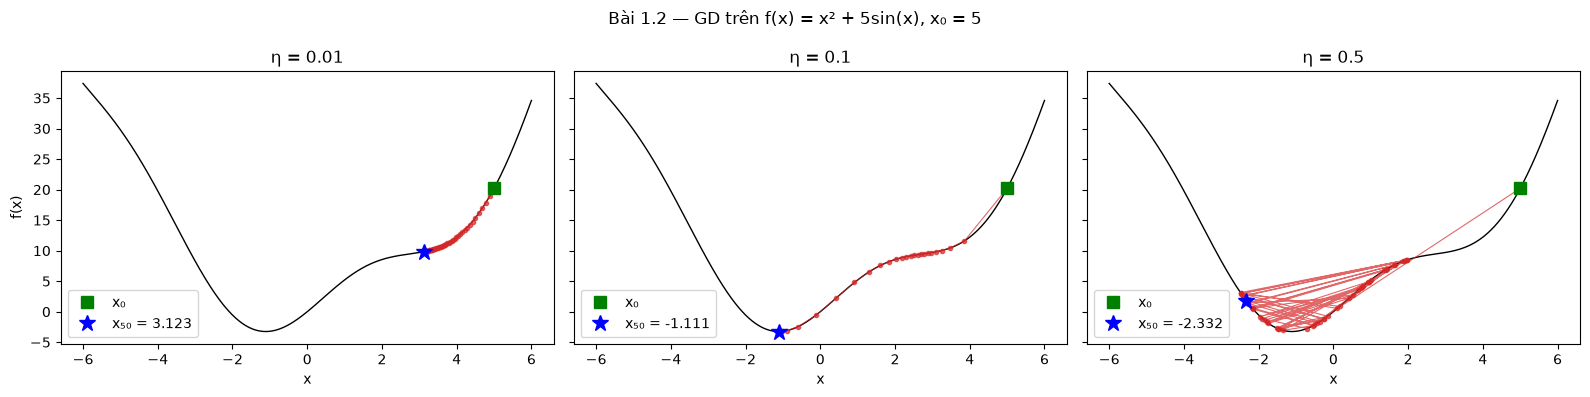

In [5]:
# 1.2 — 50 bước từ x0 = 5 với η = 0.01, 0.1, 0.5
lrs_1d = [0.01, 0.1, 0.5]
x_grid = np.linspace(-6, 6, 400)

fig, axes = plt.subplots(1, 3, figsize=(16, 4), sharey=True)
for lr, ax in zip(lrs_1d, axes):
    xs = gd_1d(df, 5.0, lr)
    ax.plot(x_grid, f(x_grid), "k", lw=1)
    ax.plot(xs, f(xs), "o-", ms=3, lw=0.8, color="tab:red", alpha=0.7)
    ax.plot(xs[0], f(xs[0]), "gs", ms=8, label="x₀")
    ax.plot(xs[-1], f(xs[-1]), "b*", ms=12, label=f"x₅₀ = {xs[-1]:.3f}")
    ax.set_title(f"η = {lr}"); ax.set_xlabel("x"); ax.legend()
axes[0].set_ylabel("f(x)")
plt.suptitle("Bài 1.2 — GD trên f(x) = x² + 5sin(x), x₀ = 5")
plt.tight_layout(); plt.show()

**Nhận xét 1.2:**
- η = 0.01: bước quá nhỏ. Sau 50 bước x mới đến khoảng 3.1, chưa tới đáy.
- η = 0.1: hội tụ nhanh về cực tiểu x* ≈ −1.1105, f(x*) ≈ −3.246.
- η = 0.5: bước quá lớn. Tại đáy f''(x*) = 2 − 5sin(x*) ≈ 6.5, nên η·f'' ≈ 3.2 > 2 và GD không ổn định quanh x*. Quỹ đạo nhảy qua lại hỗn loạn chứ không hội tụ (chỉ không bay ra vô cùng vì khi |x| lớn, hạng x² kéo x về gần 0).

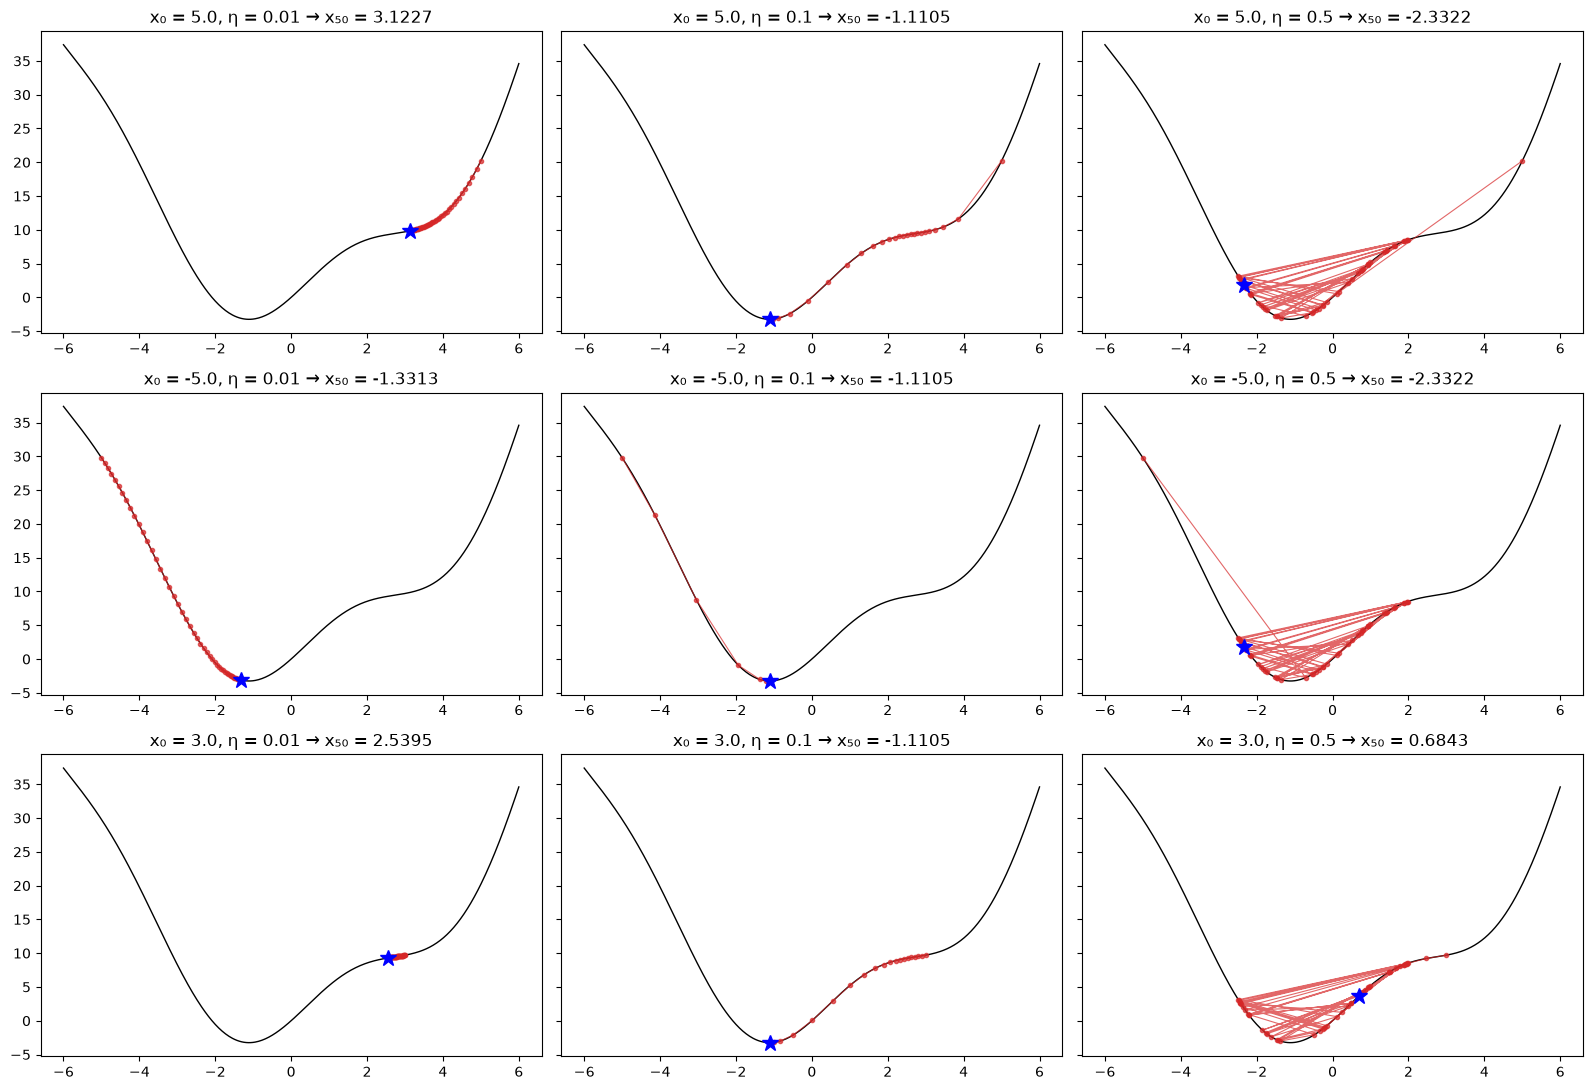

   x0      η      x_50   f(x_50)
    5   0.01    3.1227    9.8457
    5   0.10   -1.1105   -3.2464
    5   0.50   -2.3322    1.8198
   -5   0.01   -1.3313   -3.0850
   -5   0.10   -1.1105   -3.2464
   -5   0.50   -2.3322    1.8198
    3   0.01    2.5395    9.2809
    3   0.10   -1.1105   -3.2464
    3   0.50    0.6843    3.6288


In [6]:
# 1.3 — Chạy lại từ x0 = −5 và x0 = 3
starts = [5.0, -5.0, 3.0]
fig, axes = plt.subplots(len(starts), 3, figsize=(16, 11), sharey=True)
for i, x0 in enumerate(starts):
    for j, lr in enumerate(lrs_1d):
        xs = gd_1d(df, x0, lr)
        ax = axes[i, j]
        ax.plot(x_grid, f(x_grid), "k", lw=1)
        ax.plot(xs, f(xs), "o-", ms=3, lw=0.8, color="tab:red", alpha=0.7)
        ax.plot(xs[-1], f(xs[-1]), "b*", ms=12)
        ax.set_title(f"x₀ = {x0}, η = {lr} → x₅₀ = {xs[-1]:.4f}")
plt.tight_layout(); plt.show()

print(f"{'x0':>5s}{'η':>7s}{'x_50':>10s}{'f(x_50)':>10s}")
for x0 in starts:
    for lr in lrs_1d:
        x_end = gd_1d(df, x0, lr)[-1]
        print(f"{x0:5.0f}{lr:7.2f}{x_end:10.4f}{f(x_end):10.4f}")

f'(x) = 0 tại: [-1.1105]
g'(x) = 0 tại: [-1.3064  1.9774  3.8375] (cực tiểu, cực đại, cực tiểu)


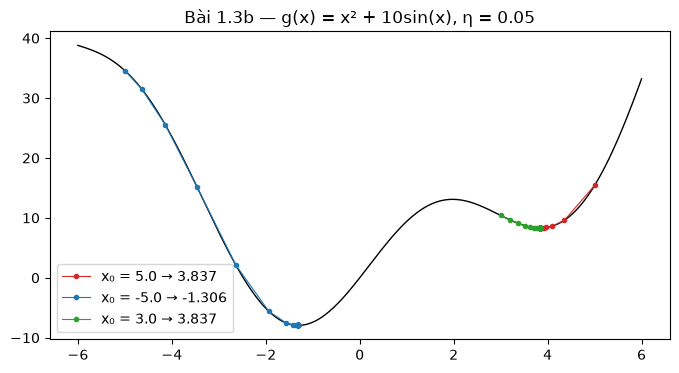

In [7]:
# 1.3b — f'(x) = 0 có bao nhiêu nghiệm? So với g(x) = x² + 10·sin(x)
def g(x):
    return x**2 + 10 * np.sin(x)

def dg(x):
    return 2 * x + 10 * np.cos(x)

def stationary_points(grad_fn, lo=-10, hi=10, num=200_001):
    xx = np.linspace(lo, hi, num)
    s = np.sign(grad_fn(xx))
    return xx[1:][s[1:] != s[:-1]]

print("f'(x) = 0 tại:", stationary_points(df))
print("g'(x) = 0 tại:", stationary_points(dg), "(cực tiểu, cực đại, cực tiểu)")

plt.figure(figsize=(8, 4))
plt.plot(x_grid, g(x_grid), "k", lw=1)
for x0, c in [(5.0, "tab:red"), (-5.0, "tab:blue"), (3.0, "tab:green")]:
    xs = gd_1d(dg, x0, 0.05)
    plt.plot(xs, g(xs), "o-", ms=3, lw=0.8, color=c, label=f"x₀ = {x0} → {xs[-1]:.3f}")
plt.legend(); plt.title("Bài 1.3b — g(x) = x² + 10sin(x), η = 0.05"); plt.show()

**Nhận xét 1.3:**
- Với f(x) = x² + 5sin(x), phương trình f'(x) = 2x + 5cos(x) = 0 chỉ có **một nghiệm** x* ≈ −1.1105. Hàm này chỉ có một cực tiểu, và nó cũng là cực tiểu toàn cục.
- Với η = 0.1, cả ba điểm xuất phát 5, −5, 3 đều về cùng x*. Khác biệt chỉ xuất hiện khi η chọn sai: η = 0.01 chưa kịp hội tụ sau 50 bước, η = 0.5 dao động hỗn loạn. Nguyên nhân ở đây là learning rate, **không phải** cực tiểu địa phương.
- Nếu tăng biên độ sin, ví dụ g(x) = x² + 10sin(x), hàm có **hai cực tiểu địa phương** (x ≈ −1.31 và x ≈ 3.84) ngăn cách bởi một cực đại (x ≈ 1.98). GD chỉ đi theo hướng dốc xuống *cục bộ*, nên điểm hội tụ phụ thuộc x₀ nằm ở "lưu vực" nào: x₀ = 5 và x₀ = 3 rơi vào cực tiểu địa phương 3.84, còn x₀ = −5 về cực tiểu toàn cục −1.31. Tại cực tiểu địa phương gradient bằng 0, nên GD dừng ở đó dù có điểm thấp hơn.
- Kết luận: với hàm không lồi, GD **không** đảm bảo về cùng một điểm. Với hàm lồi như MSE của linear regression, chỉ có một cực tiểu nên GD (với η hợp lý) luôn về nghiệm tối ưu.

## Bài 2 — Kiểm tra gradient

In [8]:
# 2.1 — loss (MSE có hệ số 1/2) và gradient giải tích
#   L(w) = 1/(2n) · ||Xw − y||²
#   ∇L(w) = 1/n · Xᵀ(Xw − y)
def loss(w, X, y):
    r = X @ w - y
    return 0.5 * np.mean(r ** 2)

def grad(w, X, y):
    return X.T @ (X @ w - y) / len(y)

In [9]:
# 2.2 — Gradient số bằng sai phân trung tâm: ∂f/∂w_i ≈ [f(w + ε·e_i) − f(w − ε·e_i)] / (2ε)
def numerical_grad(f, w, eps=1e-5):
    w = np.asarray(w, dtype=float)
    g = np.zeros_like(w)
    for i in range(w.size):
        e = np.zeros_like(w)
        e[i] = eps
        g[i] = (f(w + e) - f(w - e)) / (2 * eps)
    return g

def rel_error(a, b):
    return np.linalg.norm(a - b) / (np.linalg.norm(a) + np.linalg.norm(b))

In [10]:
# 2.3 — So sánh trên 100 mẫu California Housing (đã chuẩn hóa + bias), w ngẫu nhiên
rng = np.random.default_rng(0)
idx = rng.choice(len(Xb_train), size=100, replace=False)
X100, y100 = Xb_train[idx], y_train[idx]
w_rand = rng.normal(size=X100.shape[1])

g_ana = grad(w_rand, X100, y100)
g_num = numerical_grad(lambda w: loss(w, X100, y100), w_rand)
err = rel_error(g_ana, g_num)

print("giải tích:", g_ana)
print("số       :", g_num)
print(f"sai khác tương đối = {err:.2e}")
assert err < 1e-7, "Gradient sai!"
print("OK — gradient đúng")

giải tích: [-3.484151 -1.840179  0.458483 -0.408222  0.211539 -1.068882  0.075766
  0.324232  0.097895]
số       : [-3.484151 -1.840179  0.458483 -0.408222  0.211539 -1.068882  0.075766
  0.324232  0.097895]
sai khác tương đối = 1.95e-11
OK — gradient đúng


In [11]:
# 2.4 — Cố ý làm sai: bỏ hệ số 1/n
def grad_wrong(w, X, y):
    return X.T @ (X @ w - y)

g_bad = grad_wrong(w_rand, X100, y100)
err_bad = rel_error(g_bad, g_num)
print(f"sai khác tương đối (bỏ 1/n) = {err_bad:.4f}")
print("tỉ lệ g_bad / g_num theo từng thành phần:", g_bad / g_num)

sai khác tương đối (bỏ 1/n) = 0.9802
tỉ lệ g_bad / g_num theo từng thành phần: [100. 100. 100. 100. 100. 100. 100. 100. 100.]


**Nhận xét 2.4:** Bỏ 1/n thì gradient giải tích lớn gấp đúng n = 100 lần. Sai khác tương đối là (n − 1)/(n + 1) ≈ 0.98, rất xa ngưỡng 1e-7, nên gradient check bắt lỗi ngay. Tỉ lệ từng thành phần đều bằng 100, gợi ý lỗi nằm ở hệ số chuẩn hóa chứ không ở hướng gradient. Đây là lý do nên in thêm tỉ lệ khi check thất bại: một tỉ lệ hằng số (n, 2, 1/2...) thường là lỗi hệ số.

## Bài 3 — Ba biến thể GD

In [12]:
# 3.0 — Hàm train chung
def train_gd(X, y, lr=0.01, batch_size=None, epochs=50, momentum=0.0, seed=0):
    """batch_size=None: batch GD; 1: SGD; số khác: mini-batch.
    Trả về w và danh sách loss trên toàn tập train sau mỗi epoch."""
    rng = np.random.default_rng(seed)
    n, d = X.shape
    B = n if batch_size is None else batch_size
    w = np.zeros(d)
    v = np.zeros(d)                      # vận tốc cho momentum
    losses = []
    with np.errstate(over="ignore", invalid="ignore"):
        for _ in range(epochs):
            perm = rng.permutation(n)    # xáo trộn mỗi epoch
            for start in range(0, n, B):
                b = perm[start:start + B]
                g = grad(w, X[b], y[b])
                v = momentum * v - lr * g
                w = w + v
            losses.append(loss(w, X, y))
            if not np.isfinite(losses[-1]):   # phân kỳ: dừng sớm
                break
    return w, losses

In [13]:
# 3.1 — Nghiệm normal equation làm mốc + train ba biến thể, mỗi loại 30 epoch
w_ne = fit_normal_equation(Xb_train, y_train)
loss_opt = loss(w_ne, Xb_train, y_train)
print(f"loss tối ưu (normal equation) = {loss_opt:.6f}")

configs = {                     # (batch_size, lr)
    "Batch GD":        (None, 0.1),
    "SGD":             (1,    1e-4),
    "Mini-batch B=32": (32,   0.01),
}
results = {}
for name, (bs, lr) in configs.items():
    t0 = time.perf_counter()
    w, losses = train_gd(Xb_train, y_train, lr=lr, batch_size=bs, epochs=30)
    elapsed = time.perf_counter() - t0
    results[name] = {"losses": losses, "time": elapsed, "lr": lr}
    print(f"{name:16s} η={lr:<7g} loss cuối = {losses[-1]:.6f}   thời gian = {elapsed:.3f}s")

loss tối ưu (normal equation) = 0.258967
Batch GD         η=0.1     loss cuối = 0.307956   thời gian = 0.081s


SGD              η=0.0001  loss cuối = 0.259160   thời gian = 10.752s


Mini-batch B=32  η=0.01    loss cuối = 0.259770   thời gian = 0.233s


*Về η:* mỗi biến thể dùng η riêng. Sau chuẩn hóa vẫn có outlier (AveOccup lên tới ~107 độ lệch chuẩn). SGD cập nhật theo từng mẫu, nên một mẫu có ||x||² ≈ 10⁴ đủ làm nổ với η = 0.01 hay 0.001. Phải hạ η xuống 1e-4 SGD mới ổn định. Batch GD lấy trung bình trên cả tập nên chịu được η = 0.1 (λ_max(XᵀX/n) ≈ 2, giới hạn ổn định η < 2/λ_max ≈ 1).

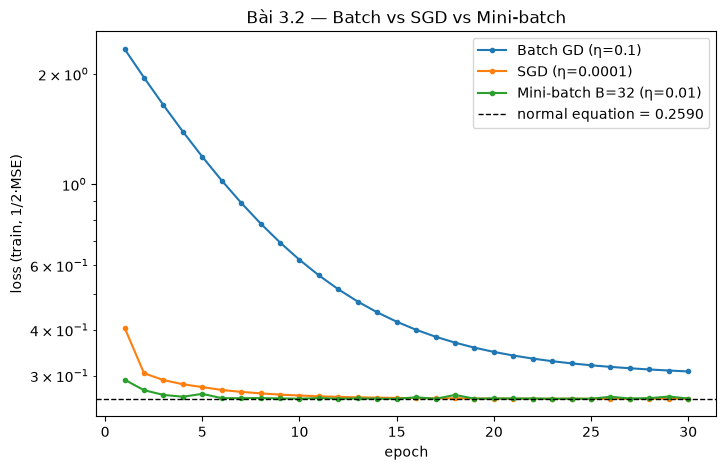

In [14]:
# 3.2 — Loss theo epoch của cả ba + đường loss tối ưu
plt.figure(figsize=(8, 5))
for name, r in results.items():
    plt.plot(range(1, len(r["losses"]) + 1), r["losses"], "o-", ms=3,
             label=f"{name} (η={r['lr']:g})")
plt.axhline(loss_opt, color="k", ls="--", lw=1, label=f"normal equation = {loss_opt:.4f}")
plt.yscale("log"); plt.xlabel("epoch"); plt.ylabel("loss (train, 1/2·MSE)")
plt.title("Bài 3.2 — Batch vs SGD vs Mini-batch"); plt.legend(); plt.show()

In [15]:
# 3.3 — Thời gian để loss < 1.01 × loss tối ưu (ước lượng = epoch đạt ngưỡng × thời gian/epoch)
def first_epoch_below(losses, thr):
    return next((i + 1 for i, l in enumerate(losses) if l < thr), None)

thr = 1.01 * loss_opt
print(f"{'':16s}{'s/epoch':>10s}{'epoch đạt':>12s}{'giây đạt':>10s}")
for name, r in results.items():
    per_epoch = r["time"] / len(r["losses"])
    ep = first_epoch_below(r["losses"], thr)
    sec = f"{ep * per_epoch:.3f}" if ep else "—"
    print(f"{name:16s}{per_epoch:10.4f}{str(ep or 'chưa'):>12s}{sec:>10s}")

                   s/epoch   epoch đạt  giây đạt
Batch GD            0.0027        chưa         —
SGD                 0.3584          14     5.018
Mini-batch B=32     0.0078           6     0.047


**Nhận xét 3.3:**
- **Mini-batch B = 32 nhanh nhất theo giây.** Chỉ vài epoch đã xuống dưới 1.01 × tối ưu, và mỗi epoch chỉ tốn vài mili-giây vì phép nhân ma trận 32 dòng vẫn được vector hóa.
- **Batch GD** có epoch rẻ nhất (một phép nhân ma trận), nhưng mỗi epoch chỉ cập nhật **một lần**, nên sau 30 epoch vẫn còn cách tối ưu khá xa.
- **SGD** cập nhật nhiều lần nhất (n lần/epoch) nhưng phải chạy vòng lặp Python từng mẫu, nên chậm hơn hàng trăm lần mỗi epoch. Thêm vào đó η phải rất nhỏ vì outlier. SGD giảm loss tốt theo epoch nhưng rất tệ theo giây.

## Bài 4 — Ảnh hưởng của learning rate

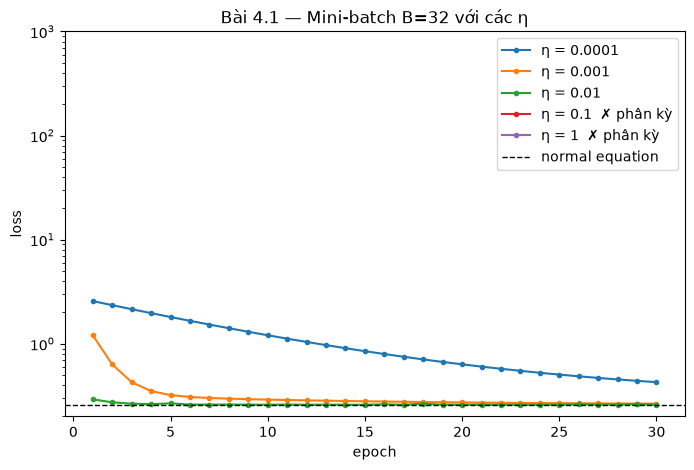

In [16]:
# 4.1 — Mini-batch B=32, η = 1e-4 … 1, 30 epoch, trục y log
lrs = [1e-4, 1e-3, 1e-2, 1e-1, 1]
lr_results = {}
plt.figure(figsize=(8, 5))
for lr in lrs:
    _, losses = train_gd(Xb_train, y_train, lr=lr, batch_size=32, epochs=30)
    lr_results[lr] = losses
    diverged = not np.isfinite(losses[-1]) or losses[-1] > losses[0]
    shown = np.minimum(losses, 1e6)          # cắt giá trị khổng lồ/inf khi vẽ
    plt.plot(range(1, len(shown) + 1), shown, "o-", ms=3,
             label=f"η = {lr:g}" + ("  ✗ phân kỳ" if diverged else ""))
plt.axhline(loss_opt, color="k", ls="--", lw=1, label="normal equation")
plt.yscale("log"); plt.ylim(0.2, 1e3)                     # đường phân kỳ vọt ra khỏi khung
plt.xlabel("epoch"); plt.ylabel("loss")
plt.title("Bài 4.1 — Mini-batch B=32 với các η"); plt.legend(); plt.show()

In [17]:
# 4.2 — Đánh dấu η phân kỳ
for lr, losses in lr_results.items():
    diverged = not np.isfinite(losses[-1]) or losses[-1] > losses[0]
    status = "PHÂN KỲ" if diverged else "hội tụ"
    print(f"η = {lr:<7g} {status:8s} loss cuối = {losses[-1]:.4g}  (dừng ở epoch {len(losses)})")

η = 0.0001  hội tụ   loss cuối = 0.4276  (dừng ở epoch 30)
η = 0.001   hội tụ   loss cuối = 0.2654  (dừng ở epoch 30)
η = 0.01    hội tụ   loss cuối = 0.2598  (dừng ở epoch 30)
η = 0.1     PHÂN KỲ  loss cuối = 2.029e+134  (dừng ở epoch 30)
η = 1       PHÂN KỲ  loss cuối = inf  (dừng ở epoch 14)


**Nhận xét 4.2:**
- **Phân kỳ:** η = 0.1 và η = 1. Với η = 1, loss thành inf/nan chỉ sau vài epoch (đường bị cắt ngắn trên hình).
- η = 1e-4 hội tụ nhưng quá chậm: sau 30 epoch vẫn cách tối ưu rõ rệt.
- **Khoảng η "tốt" ≈ 1e-3 đến 1e-2.** η = 1e-2 xuống sát tối ưu chỉ sau vài epoch. Vì 0.1 đã phân kỳ, biên trên nằm đâu đó giữa 1e-2 và 1e-1.

B =   8: loss cuối = 1.216e+74,  std loss epoch 11–30 = 2.65e+73


B =  32: loss cuối = 0.2598,  std loss epoch 11–30 = 1.60e-03
B = 256: loss cuối = 0.2626,  std loss epoch 11–30 = 5.79e-03


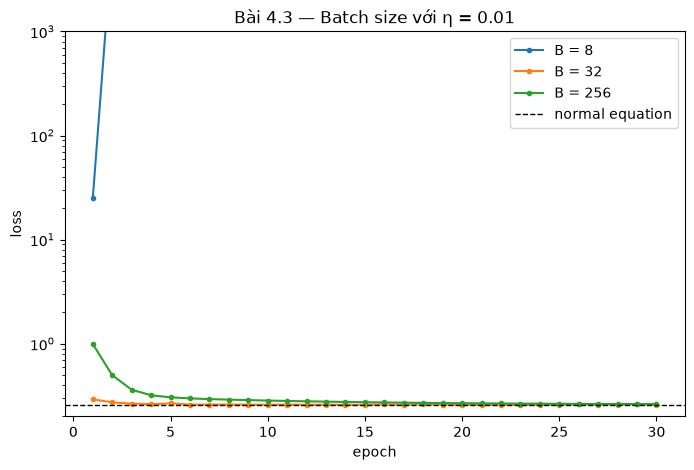

In [18]:
# 4.3 — Batch size 8, 32, 256 với η tốt nhất (1e-2)
best_lr = 1e-2
plt.figure(figsize=(8, 5))
for bs in [8, 32, 256]:
    _, losses = train_gd(Xb_train, y_train, lr=best_lr, batch_size=bs, epochs=30)
    tail = np.array(losses[10:])
    print(f"B = {bs:3d}: loss cuối = {losses[-1]:.4g},  std loss epoch 11–30 = {np.std(tail):.2e}")
    plt.plot(range(1, len(losses) + 1), np.minimum(losses, 1e6), "o-", ms=3, label=f"B = {bs}")
plt.axhline(loss_opt, color="k", ls="--", lw=1, label="normal equation")
plt.yscale("log"); plt.ylim(0.2, 1e3)
plt.xlabel("epoch"); plt.ylabel("loss")
plt.title(f"Bài 4.3 — Batch size với η = {best_lr}"); plt.legend(); plt.show()

**Nhận xét 4.3:**
- **B = 8 phân kỳ** dù η = 0.01 tốt với B = 32. Batch nhỏ thì gradient nhiễu hơn: một batch 8 mẫu chứa outlier kéo gradient rất mạnh, và η "tốt" cho batch lớn trở thành quá lớn cho batch nhỏ. Batch nhỏ cần η nhỏ hơn.
- **B = 32** dao động nhẹ quanh tối ưu: loss nhảy lên xuống ở mức ~1e-3 từ epoch này sang epoch khác, không giảm đơn điệu.
- **B = 256** mượt hơn nhưng mỗi epoch ít bước cập nhật hơn 8 lần, nên sau 30 epoch vẫn chưa sát tối ưu bằng B = 32. Std ở đây chủ yếu phản ánh loss còn đang giảm dần, không phải dao động.
- Quy luật: batch càng nhỏ thì nhiễu càng lớn, mỗi epoch có nhiều bước hơn, và cần η nhỏ hơn.

## Bài 5 — Momentum

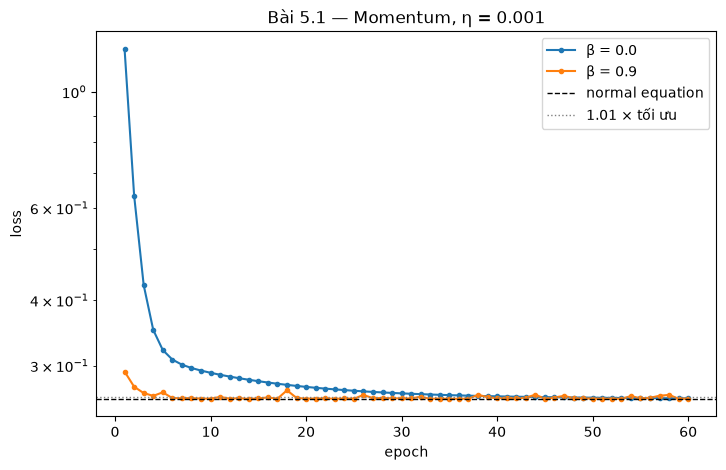

In [19]:
# 5.1 — Mini-batch B=32, cùng η = 1e-3, có và không có momentum β = 0.9
lr_m = 1e-3
mom_results = {}
plt.figure(figsize=(8, 5))
for beta in [0.0, 0.9]:
    _, losses = train_gd(Xb_train, y_train, lr=lr_m, batch_size=32, epochs=60, momentum=beta)
    mom_results[beta] = losses
    plt.plot(range(1, len(losses) + 1), losses, "o-", ms=3, label=f"β = {beta}")
plt.axhline(loss_opt, color="k", ls="--", lw=1, label="normal equation")
plt.axhline(1.01 * loss_opt, color="gray", ls=":", lw=1, label="1.01 × tối ưu")
plt.yscale("log"); plt.xlabel("epoch"); plt.ylabel("loss")
plt.title(f"Bài 5.1 — Momentum, η = {lr_m}"); plt.legend(); plt.show()

In [20]:
# 5.2 — Số epoch để loss < 1.01 × loss tối ưu
for beta, losses in mom_results.items():
    print(f"β = {beta}: {first_epoch_below(losses, 1.01 * loss_opt)} epoch")

β = 0.0: 43 epoch
β = 0.9: 6 epoch


**Nhận xét 5.2:** Cùng η = 1e-3, momentum β = 0.9 chỉ cần ~6 epoch, còn không momentum cần ~43 epoch. Momentum tích lũy vận tốc nên bước hiệu dụng xấp xỉ η/(1 − β) = 10η.

Hệ quả là momentum và η không độc lập. Với η = 0.01 (η tốt khi không có momentum), β = 0.9 cho bước hiệu dụng ~0.1 và **phân kỳ**, giống η = 0.1 ở Bài 4. Vì vậy khi bật momentum thường phải giảm η.

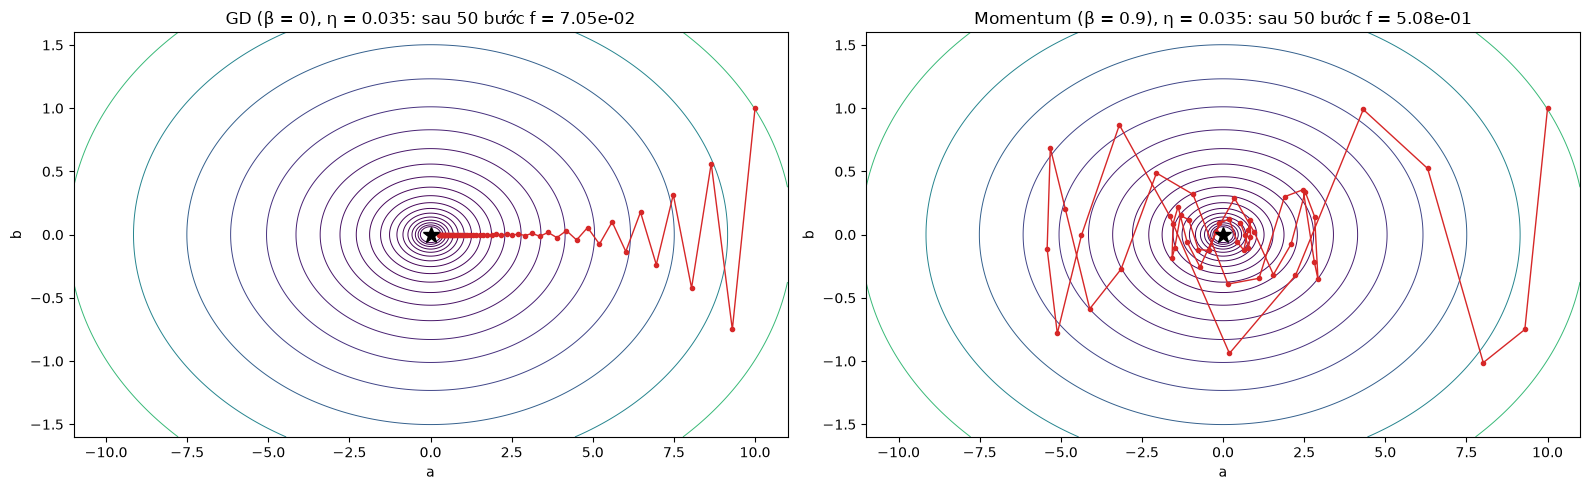

In [21]:
# 5.3 — Bài thêm: f(a, b) = a² + 25b², GD có/không momentum từ (10, 1)
def f2(p):
    a, b = p
    return a**2 + 25 * b**2

def grad_f2(p):
    a, b = p
    return np.array([2 * a, 50 * b])

def gd_2d(p0, lr, steps, beta=0.0):
    p, v = np.array(p0, dtype=float), np.zeros(2)
    path = [p.copy()]
    for _ in range(steps):
        v = beta * v - lr * grad_f2(p)
        p = p + v
        path.append(p.copy())
    return np.array(path)

lr2, steps2 = 0.035, 50
paths = {"GD (β = 0)": gd_2d((10, 1), lr2, steps2),
         "Momentum (β = 0.9)": gd_2d((10, 1), lr2, steps2, beta=0.9)}

A, Bm = np.meshgrid(np.linspace(-11, 11, 300), np.linspace(-1.6, 1.6, 300))
Z = A**2 + 25 * Bm**2
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
for ax, (name, path) in zip(axes, paths.items()):
    ax.contour(A, Bm, Z, levels=np.logspace(-1, np.log10(Z.max()), 20), cmap="viridis", linewidths=0.7)
    ax.plot(path[:, 0], path[:, 1], "o-", ms=3, lw=1, color="tab:red")
    ax.plot(0, 0, "k*", ms=12)
    ax.set_title(f"{name}, η = {lr2}: sau {steps2} bước f = {f2(path[-1]):.2e}")
    ax.set_xlabel("a"); ax.set_ylabel("b")
plt.tight_layout(); plt.show()

**Nhận xét 5.3:**
- Hàm có độ cong theo b lớn gấp 25 lần theo a: thung lũng hẹp dài dọc trục a. η bị giới hạn bởi hướng dốc nhất (η < 2/50 = 0.04). Với η = 0.035, hệ số nhân theo b là 1 − 50η = −0.75, nên b **đổi dấu mỗi bước**. Đó là hiện tượng **zigzag** qua lại giữa hai vách thung lũng. Trong khi đó theo a chỉ giảm (1 − 2η) = 0.93 mỗi bước, tức tiến rất chậm.
- Với momentum, các thành phần dao động theo b triệt tiêu nhau khi cộng dồn vận tốc, còn thành phần theo a cùng dấu nên được cộng dồn và tăng tốc. Quỹ đạo bớt zigzag, đi thẳng dọc đáy thung lũng hơn và về gần (0, 0) nhanh hơn nhiều sau cùng số bước. Momentum có thể vọt quá đích một chút rồi quay lại.

## Bài 6 — Không chuẩn hóa thì sao

In [22]:
# 6.1 — Batch GD trên dữ liệu chưa chuẩn hóa: tìm η lớn nhất không phân kỳ (100 epoch)
def diverges(lr, X, y, epochs=100):
    _, losses = train_gd(X, y, lr=lr, batch_size=None, epochs=epochs)
    return (not np.isfinite(losses[-1])) or losses[-1] > loss(np.zeros(X.shape[1]), X, y)

# quét thô theo log
for lr in [1e-8, 1e-7, 1e-6, 1e-5, 1e-4]:
    print(f"η = {lr:g}: {'phân kỳ' if diverges(lr, Xb_raw, y_train) else 'ổn'}")

# chia đôi trong [1e-7, 1e-6] (thang log)
lo, hi = 1e-7, 1e-6
for _ in range(30):
    mid = np.sqrt(lo * hi)
    if diverges(mid, Xb_raw, y_train):
        hi = mid
    else:
        lo = mid
lr_max_raw = lo
lam_max = np.linalg.eigvalsh(Xb_raw.T @ Xb_raw / len(Xb_raw)).max()
print(f"\nη lớn nhất không phân kỳ ≈ {lr_max_raw:.4e}")
print(f"lý thuyết 2/λ_max(XᵀX/n)  = {2 / lam_max:.4e}")

η = 1e-08: ổn


η = 1e-07: ổn


η = 1e-06: phân kỳ


η = 1e-05: phân kỳ
η = 0.0001: phân kỳ



η lớn nhất không phân kỳ ≈ 5.9971e-07
lý thuyết 2/λ_max(XᵀX/n)  = 5.9924e-07


loss tối ưu                    = 0.258967
raw,    η=5.40e-07, 100 epoch = 1.089808  (gấp 4.21 lần tối ưu)
scaled, η=0.1,      100 epoch = 0.273758  (gấp 1.057 lần tối ưu)

số điều kiện κ (raw)    = 5.64e+10
số điều kiện κ (scaled) = 4.28e+01


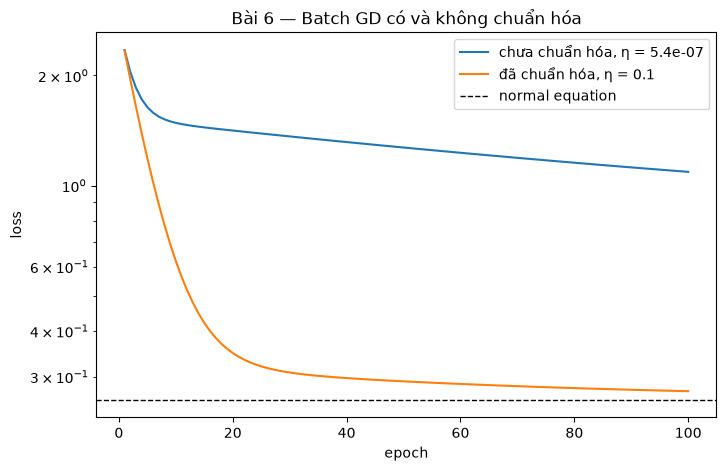

In [23]:
# 6.2 — Với η an toàn (hơi dưới ngưỡng), sau 100 epoch loss cách tối ưu bao xa?
w_ne_raw = fit_normal_equation(Xb_raw, y_train)
loss_opt_raw = loss(w_ne_raw, Xb_raw, y_train)        # bằng loss_opt: chuẩn hóa không đổi nghiệm

lr_raw = 0.9 * lr_max_raw                              # lùi 10% khỏi biên để không dao động
_, losses_raw = train_gd(Xb_raw, y_train, lr=lr_raw, batch_size=None, epochs=100)
_, losses_s   = train_gd(Xb_train, y_train, lr=0.1, batch_size=None, epochs=100)

print(f"loss tối ưu                    = {loss_opt_raw:.6f}")
print(f"raw,    η={lr_raw:.2e}, 100 epoch = {losses_raw[-1]:.6f}  (gấp {losses_raw[-1] / loss_opt_raw:.2f} lần tối ưu)")
print(f"scaled, η=0.1,      100 epoch = {losses_s[-1]:.6f}  (gấp {losses_s[-1] / loss_opt:.3f} lần tối ưu)")

eig_raw = np.linalg.eigvalsh(Xb_raw.T @ Xb_raw / len(Xb_raw))
eig_s   = np.linalg.eigvalsh(Xb_train.T @ Xb_train / len(Xb_train))
print(f"\nsố điều kiện κ (raw)    = {eig_raw.max() / eig_raw.min():.2e}")
print(f"số điều kiện κ (scaled) = {eig_s.max() / eig_s.min():.2e}")

plt.figure(figsize=(8, 5))
plt.plot(range(1, 101), losses_raw, label=f"chưa chuẩn hóa, η = {lr_raw:.1e}")
plt.plot(range(1, 101), losses_s, label="đã chuẩn hóa, η = 0.1")
plt.axhline(loss_opt, color="k", ls="--", lw=1, label="normal equation")
plt.yscale("log"); plt.xlabel("epoch"); plt.ylabel("loss")
plt.title("Bài 6 — Batch GD có và không chuẩn hóa"); plt.legend(); plt.show()

**Nhận xét 6.3:**
Chưa chuẩn hóa, các đặc trưng có thang đo chênh nhau rất xa (Population ~ hàng nghìn, MedInc ~ vài đơn vị). Ma trận XᵀX/n có λ_max ~ 3·10⁶ và số điều kiện κ ~ 10¹⁰, tức mặt loss là một thung lũng cực kỳ hẹp và dài. Như mục 1.4, η bị chặn bởi hướng cong nhất (η < 2/λ_max ≈ 6·10⁻⁷), nên theo các hướng thoải (MedInc, bias...) mỗi bước gần như không nhúc nhích. Kết quả là sau 100 epoch loss vẫn gấp vài lần tối ưu và chưa có dấu hiệu sắp hội tụ. Chuẩn hóa đưa các hướng về cùng thang (κ ≈ 43), cho phép η lớn hơn ~10⁵ lần: cùng 100 epoch, loss chỉ còn cách tối ưu ~6%. Nghiệm tối ưu thì không đổi, chỉ có đường đi của GD thay đổi.

## Tự kiểm tra

**1. Loss tăng dần rồi thành nan sau vài epoch. Nguyên nhân thường gặp nhất?**
Learning rate quá lớn (η > 2/λ_max). Mỗi bước vọt qua đáy xa hơn bước trước nên w và loss tăng theo cấp số nhân, tràn số thành inf rồi nan. Các nguyên nhân hay đi kèm: dữ liệu chưa chuẩn hóa hoặc có outlier lớn (làm λ_max lớn), batch quá nhỏ, hoặc gradient sai hệ số (ví dụ quên 1/n ở Bài 2 tương đương nhân η lên n lần).

**2. n = 10.000, B = 64: một epoch có bao nhiêu iteration?**
⌈10000/64⌉ = **157** iteration: 156 batch đủ 64 mẫu và 1 batch cuối 16 mẫu. Nếu bỏ batch lẻ (drop_last) thì là 156.

**3. Vì sao phải xáo trộn dữ liệu mỗi epoch?**
Để mỗi mini-batch là một mẫu ngẫu nhiên đại diện cho toàn tập, nhờ đó gradient của batch là ước lượng không chệch của gradient thật. Nếu dữ liệu có thứ tự (sắp theo nhãn, theo thời gian, theo vùng), các batch liên tiếp sẽ kéo w lệch về một phía rồi lại kéo ngược lại, gây dao động và hội tụ kém. Xáo trộn lại **mỗi** epoch thì thứ tự batch không lặp lại, tránh để mô hình bị chu kỳ hóa theo một thứ tự cố định.

**4. Momentum giúp gì trong thung lũng hẹp? β = 0.99 so với 0.9?**
Trong thung lũng hẹp, gradient theo hướng ngang đổi dấu liên tục (zigzag) còn theo hướng dọc đáy thì cùng dấu. Momentum lấy trung bình trượt các gradient: thành phần zigzag triệt tiêu nhau, thành phần dọc đáy cộng dồn. Kết quả là giảm dao động và tăng tốc theo hướng đúng (Bài 5.3). β là "trí nhớ" của vận tốc: bước hiệu dụng ≈ η/(1 − β), tức ~10η với β = 0.9 và ~100η với β = 0.99. β = 0.99 tăng tốc mạnh hơn và làm mượt nhiễu tốt hơn, nhưng quán tính lớn nên dễ vọt quá đáy, dao động lâu mới tắt, phản ứng chậm khi địa hình đổi, và thường phải giảm η đi nhiều để không phân kỳ.

**5. Linear regression có nghiệm đóng, vậy khi nào nên dùng GD thay thế?**
- Số đặc trưng d lớn: normal equation tốn O(nd² + d³) và bộ nhớ d×d, còn GD mỗi bước chỉ O(nd).
- n quá lớn không vừa bộ nhớ, hoặc dữ liệu đến dạng stream/online: mini-batch/SGD xử lý từng phần.
- Ma trận thưa và rất lớn: GD tận dụng phép nhân thưa, còn XᵀX có thể bị dày đặc.
- Loss không còn nghiệm đóng: Lasso (L1), Huber, logistic regression, neural network. Học GD qua linear regression là để dùng cho các bài này.
- Chỉ cần nghiệm gần đúng nhanh, hoặc muốn early stopping như một cách regularize.

**6. Gradient check cho sai khác tương đối 0.3. Bạn sẽ kiểm tra những gì?**
- **Công thức gradient:** thiếu/thừa hệ số (1/n, 1/2, 2), sai dấu (Xw − y thay vì y − Xw), sai transpose/shape (X thay vì Xᵀ, broadcasting (n,) với (n,1) tạo ra ma trận n×n).
- **Loss và gradient có khớp nhau không:** loss dùng mean mà grad dùng sum, loss có 1/2 mà grad không, có regularization ở loss nhưng quên trong grad (hoặc phạt cả bias ở một bên).
- **So từng thành phần:** in tỉ lệ g_ana/g_num. Tỉ lệ hằng số nghĩa là lỗi hệ số; chỉ sai ở bias nghĩa là lỗi cột bias; sai lung tung nghĩa là lỗi công thức hoặc shape.
- **Bản thân gradient check:** ε quá lớn hoặc quá nhỏ (thử 1e-4…1e-7), dùng float32 thay vì float64, hàm f có ngẫu nhiên (dropout, batch khác nhau giữa hai lần gọi), w bị sửa in-place trong lúc tính, hàm không khả vi tại điểm kiểm tra (ReLU, |x|).
- **Kiểm tra trên bài toán nhỏ:** vài mẫu, vài chiều, dữ liệu đã chuẩn hóa, để loại trừ sai số số học do giá trị quá lớn.